In [ ]:
import pandas as pd
import numpy as mp
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from imblearn.over_sampling import SMOTE



## Partie 1 : Introduction au Dataset

# 1-Chargement du dataset

In [116]:
train=pd.read_csv(r'C:\Users\yassine\Desktop\projects\titanic\train.csv')
test = pd.read_csv(r'C:\Users\yassine\Desktop\projects\titanic\test.csv')

# 2-Explorer les données

In [103]:
#train.head()
train.sample()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
22,23,1,3,"McGowan, Miss. Anna ""Annie""",female,15.0,0,0,330923,8.0292,NaN,Q


In [7]:
train.shape

(891, 12)

In [8]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [7]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [40]:
null=train.isnull().sum()
null[null>0]

Age         177
Cabin       687
Embarked      2
dtype: int64

<Axes: >

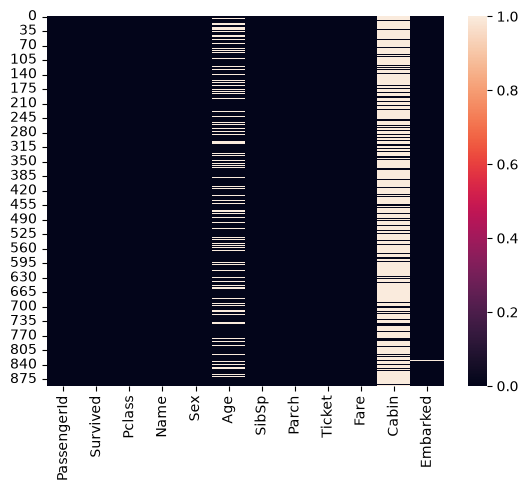

In [41]:
sns.heatmap(train.isnull())

## Partie 2 : Nettoyage des Données

In [119]:
def clean (n) :
   n.drop(['Cabin', 'Name', 'Embarked', 'Fare', 'Ticket'], axis=1, inplace=True)## delet column
   n.Age= train.Age.fillna(n.Age.median())
   n.dropna()
   return n
  

## 1. Gestion des valeurs manquantes


In [120]:
clean(train)

C:\Users\yassine\AppData\Local\Temp\ipykernel_29676\269440895.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  n.drop(['Cabin', 'Name', 'Embarked', 'Fare', 'Ticket'], axis=1, inplace=True)## delet column


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Sex_male
0,1,0,3,22.0,1,0,1
1,2,1,1,38.0,1,0,0
2,3,1,3,26.0,0,0,0
3,4,1,1,35.0,1,0,0
4,5,0,3,35.0,0,0,1
...,...,...,...,...,...,...,...
886,887,0,2,27.0,0,0,1
887,888,1,1,19.0,0,0,0
888,889,0,3,28.0,1,2,0
889,890,1,1,26.0,0,0,1


In [121]:
clean(test)

C:\Users\yassine\AppData\Local\Temp\ipykernel_29676\269440895.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  n.drop(['Cabin', 'Name', 'Embarked', 'Fare', 'Ticket'], axis=1, inplace=True)## delet column


,PassengerId,Pclass,Age,SibSp,Parch,Sex_male
0,892,3,22.0,0,0,1
1,893,3,38.0,1,0,0
2,894,2,26.0,0,0,1
3,895,3,35.0,0,0,1
4,896,3,35.0,1,1,0
...,...,...,...,...,...,...
413,1305,3,28.0,0,0,1
414,1306,1,44.0,0,0,0
415,1307,3,28.0,0,0,1
416,1308,3,34.0,0,0,1


<Axes: >

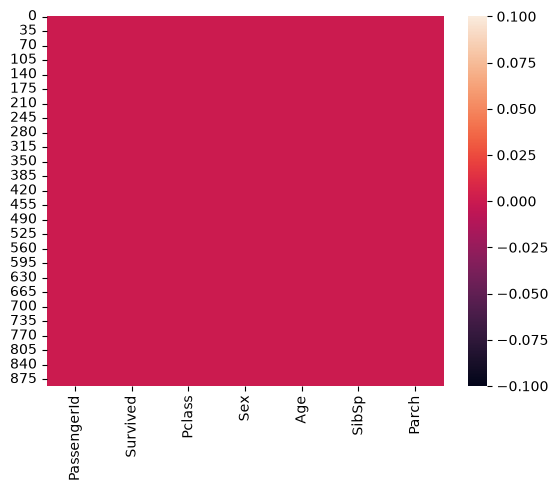

In [74]:
sns.heatmap(train.isnull())

## Partie 3 : Transformation des Données

In [77]:
vz=train.corr(numeric_only=True)

<Axes: >

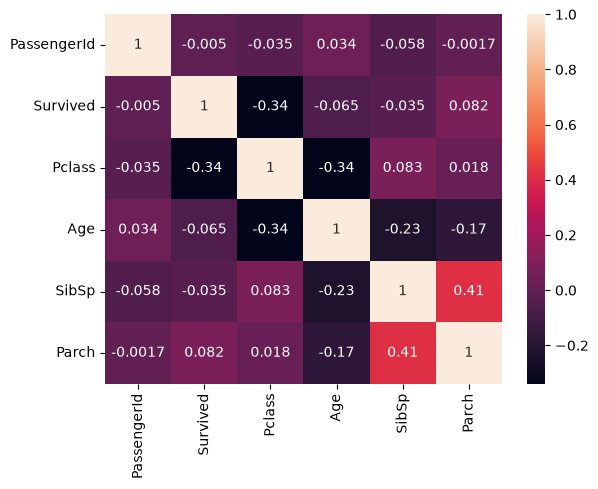

In [80]:
sns.heatmap(vz,annot=True)

<Axes: xlabel='Sex', ylabel='count'>

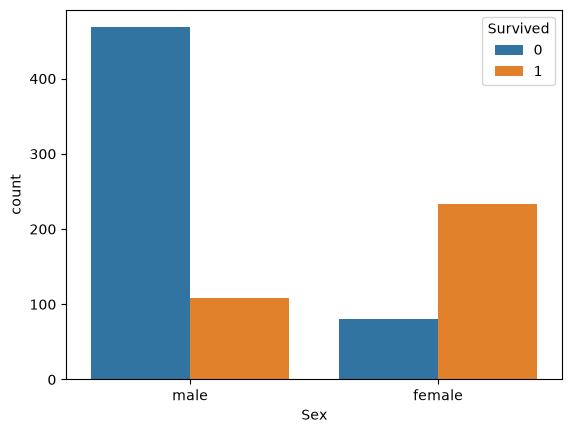

In [86]:
sns.countplot(data=train, x='Sex', hue='Survived')

<Axes: xlabel='Pclass', ylabel='count'>

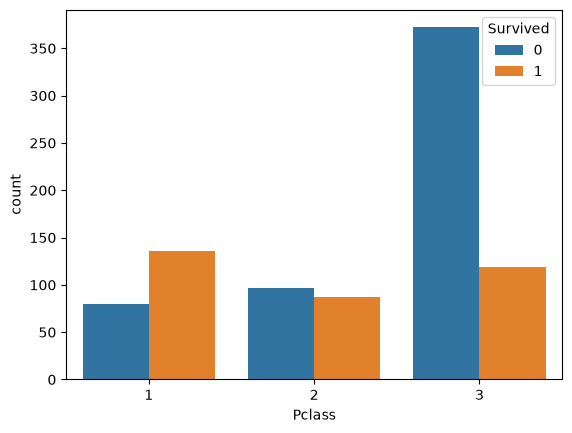

In [87]:
sns.countplot(data=train, x='Pclass', hue='Survived')

## 1. Encodage des variables catégorielles :

In [126]:
train

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Sex_male
0,1,0,3,22.0,1,0,1
1,2,1,1,38.0,1,0,0
2,3,1,3,26.0,0,0,0
3,4,1,1,35.0,1,0,0
4,5,0,3,35.0,0,0,1
...,...,...,...,...,...,...,...
886,887,0,2,27.0,0,0,1
887,888,1,1,19.0,0,0,0
888,889,0,3,28.0,1,2,0
889,890,1,1,26.0,0,0,1


## Partie 4 : Gestion des Données Déséquilibrées

In [128]:
x=train.drop(['Survived'],axis=1)
y=train.Survived

In [130]:
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=.8)

In [131]:
smote = SMOTE()
x_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)

In [134]:
model_smote = DecisionTreeClassifier()
model_smote.fit(x_train_smote, y_train_smote)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [135]:
pre_smote = model_smote.predict(x_test)
accuracy_score(pre_smote, y_test)

0.7541899441340782